In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

# Exoplanet Archive aggregate (not used here since the bias maps moved to Bias_Maps.ipynb)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

u, u_B = DEFAULT_U, DEFAULT_U_B   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)

In [3]:
# Albedos (baseline settings, HItargets_utils.py)
A_B = DEFAULT_A_B                         # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

In [4]:
# Filter to be used
instrument = "MIRI/LRS" # "JWST_NIRSpec.G395H_NRS1"  # "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

## Detectability and parameter bias analysis

The detection error per minute comes from PandExo for the planet and instrument set above (printed below). For comparison, K2-141 b has 154.5 ppm per minute (PandExo, MIRI/LRS 5.0–10.5 µm).


In [5]:
n_bins = DEFAULT_N_BINS # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes]
sigma_1min = rms_1min(planet, instrument)
n_orbits = DEFAULT_N_ORBITS # number of orbits observed


l1, l2 = lrs_range

A_B_true = A_B  # injected Bond albedo of the hyperillumination truth

# context for the bias-analysis functions imported from simple_bias_analysis.py (fit ranges A_B_FIT_BOUNDS, F_BOUNDS by default: A_B_fit may go below 0)
cfg = FittingConfig(planet=planet, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_B=u_B, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

TOI-2431 b [MIRI/LRS]: sigma_1min = 62.93 ppm/min from the PandExo cache (pandexo_cache.csv)

Noise Level (1min) = 62.9 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin = 8.1 ppm


### 1. Pure Detectability

In [6]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t_k, pc_k, fp_k = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="hyperillum", u_B=u_B)
t_n, pc_n, fp_n = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="naive", u_B=u_B)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, lc_k, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="hyperillum", u_B=u_B, include_transit=False)
_, lc_n, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA, insolation_model="naive",      u_B=u_B, include_transit=False)

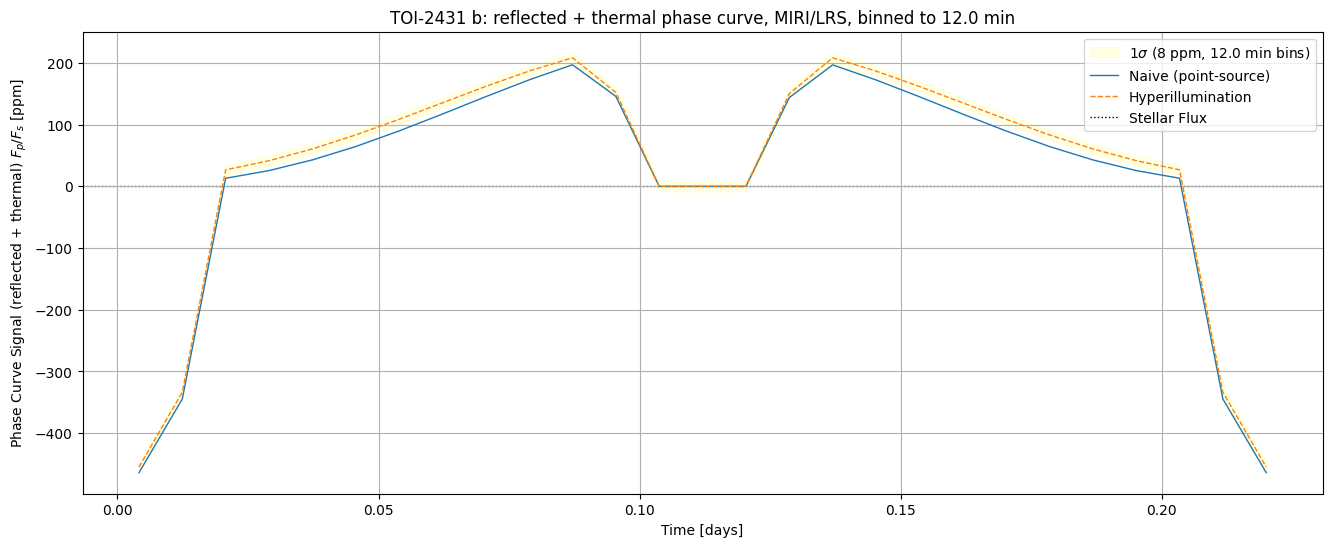

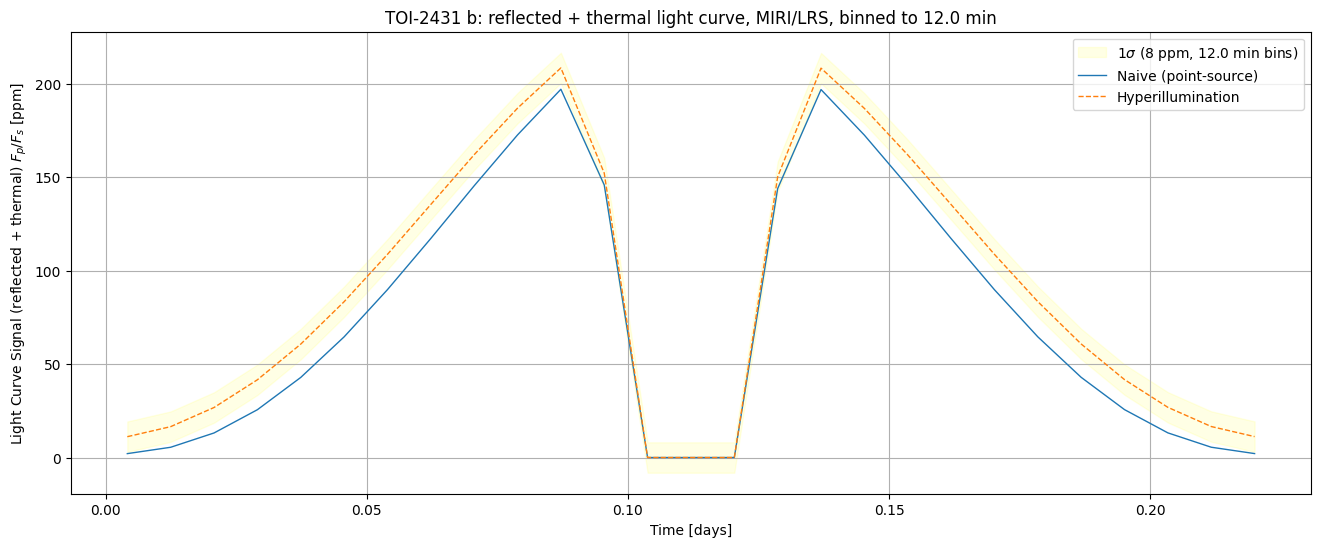

In [7]:
PAPER_MODE = False
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")
stellar_flux_line()

plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
paper_figure(f"abbias_phasecurve_binned_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
paper_figure(f"abbias_lightcurve_binned_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

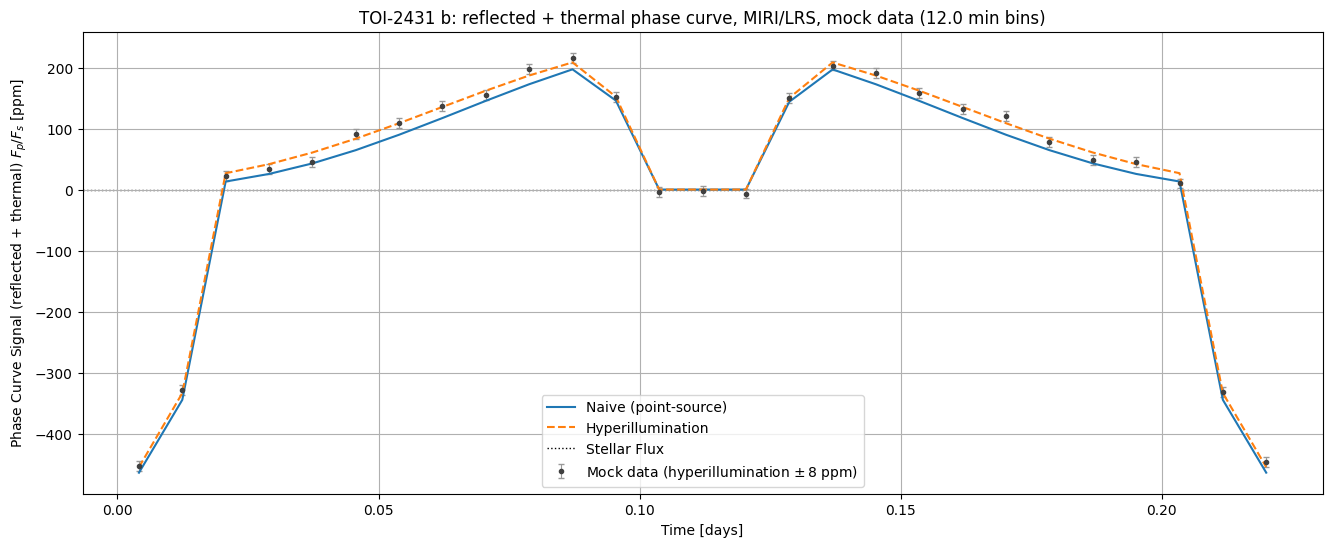

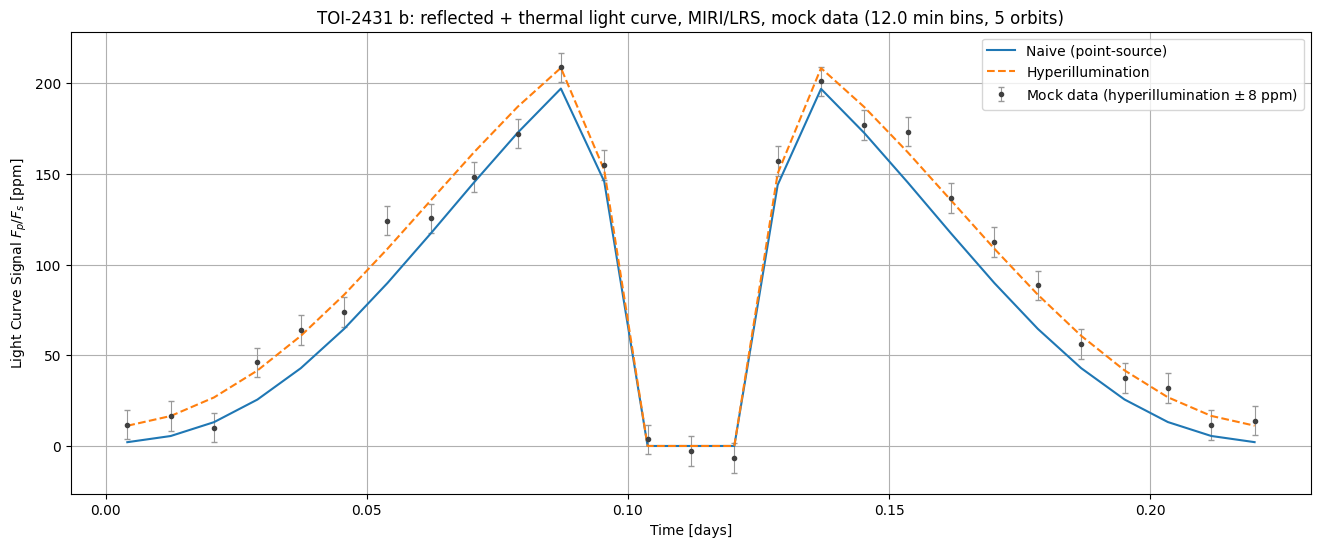

In [8]:
PAPER_MODE = False
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillum, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
stellar_flux_line()
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, mock data ({minutes_binning:.1f} min bins)")
plt.legend(); plt.grid()
paper_figure(f"abbias_phasecurve_mock_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (point-source)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, mock data ({minutes_binning:.1f} min bins, {n_orbits} orbits)")
plt.legend(); plt.grid()
paper_figure(f"abbias_lightcurve_mock_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected - 1-Parameter Fit

In [9]:
# demo: fit the naive model to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    print(f"A_B: {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} "
          f"({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  chi2={chi2:.3f}  "
          f"resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma "
          f"({cfg.n_orbits} orbits, {cfg.n_bins} bins)")

A_B: 0.200 -> 0.140  bias=-0.060 (-29.9%)  chi2=12.635  resid_rms=5.57 ppm  significance=3.55 sigma (5 orbits, 27 bins)
A_B: 0.200 -> -0.053  bias=-0.253 (-126.5%)  chi2=32.778  resid_rms=8.97 ppm  significance=5.73 sigma (5 orbits, 27 bins)


free offset="False" not really meaningful since normalization has error...

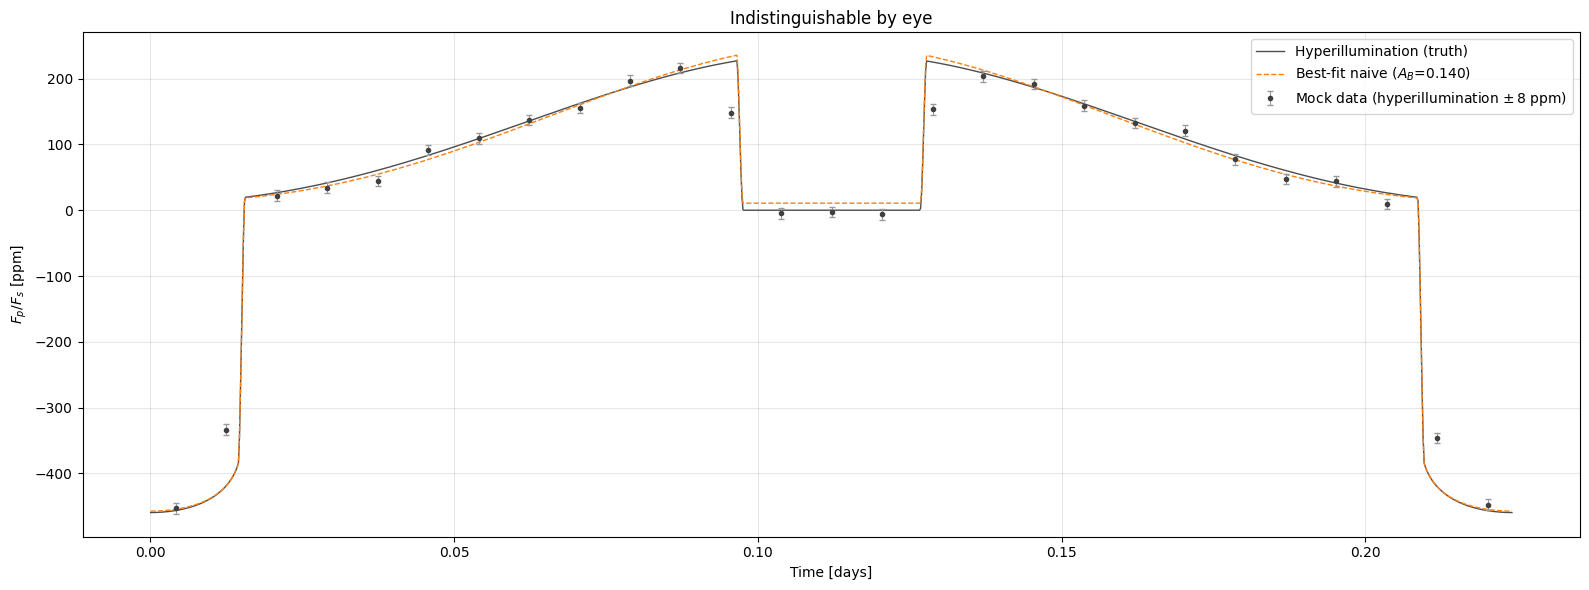

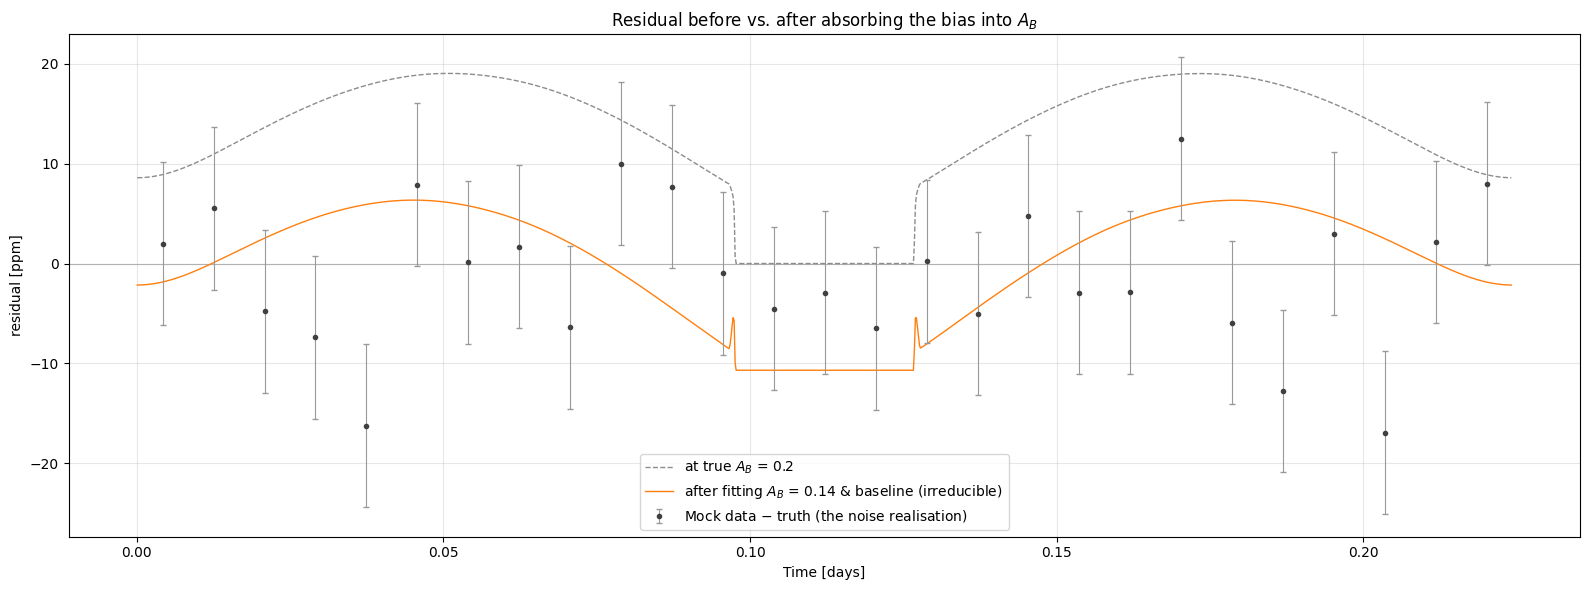

In [10]:
PAPER_MODE = False
# before vs after absorbing the bias into A_B
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(43).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.
mock_kw = dict(fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2, zorder=5)

# Figure 1: truth vs best-fit naive
fig, ax = plt.subplots(figsize=(16, 6))
ax.errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **mock_kw)
ax.plot(t_, truth,   lw=1, color="0.3", label="Hyperillumination (truth)")
ax.plot(t_, naive_f, lw=1, ls="--", color="C1", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax.set_ylabel(r"$F_p/F_s$ [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title("Indistinguishable by eye")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
paper_figure(f"abbias_fit_vs_truth_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

# Figure 2: both residuals combined on one axes, with the same mock data as the noise the bias has to beat
fig, ax = plt.subplots(figsize=(16, 6))
ax.axhline(0., color="0.7", lw=.8, zorder=1)
ax.errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **mock_kw)
ax.plot(t_, truth - naive_0, lw=1, ls="--", color="0.55", label=rf"at true $A_B$ = {A_B_true:.1f}")
ax.plot(t_, truth - naive_f, lw=1, color="C1", label=rf"after fitting $A_B$ = {A_fit:.2f} & baseline (irreducible)")
ax.set_ylabel("residual [ppm]"); ax.set_xlabel("Time [days]")
ax.set_title(r"Residual before vs. after absorbing the bias into $A_B$")
ax.grid(alpha=.3); ax.legend()
fig.tight_layout()
paper_figure(f"abbias_residuals_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

### 3. Bias vs. true Bond albedo $A_B$

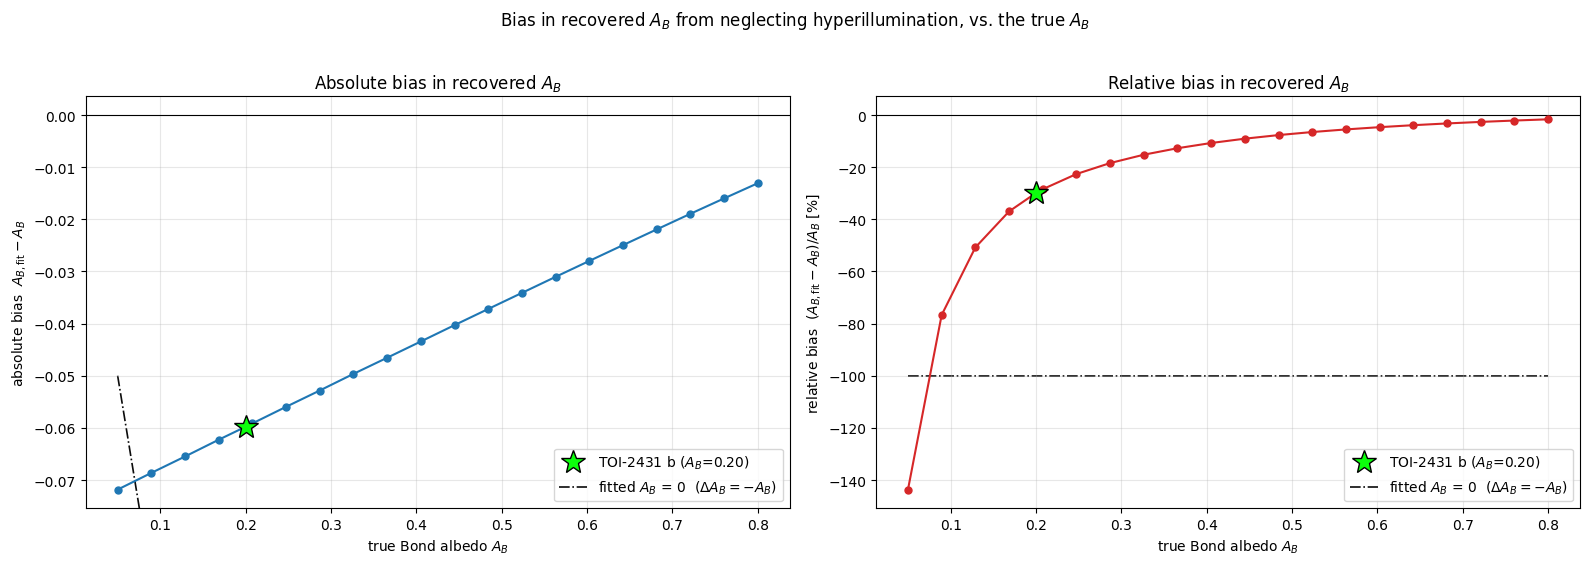

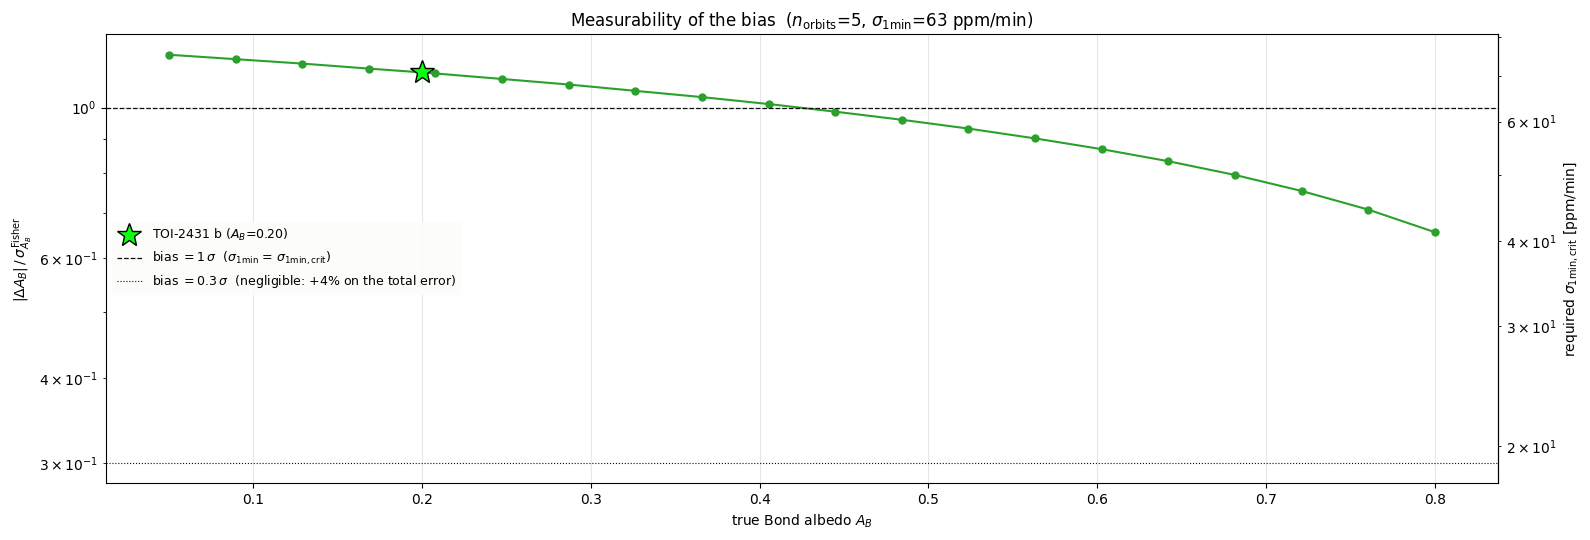

fitted A_B < 0 for true A_B <= 0.05
at TOI-2431 b (A_B=0.20): bias -0.0598,  sigma_A_B = 0.0531  ->  |bias|/sigma = 1.13
   sigma_1min = 62.9 ppm/min,  sigma_1min_crit = 70.9 ppm/min  ->  0.9x finer photometry, or 4 orbits instead of 5, before the bias reaches 1 sigma


In [11]:
PAPER_MODE = False
# Vary the TRUE Bond albedo and refit the naive model at each value (single target geometry,
# free baseline; free_offset=False is not meaningful here -- see 2.). Bias = A_fit - A_B_true.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))

# naive fit at each true A_B (A_fit in A_B_FIT_BOUNDS, so it can go below the physical floor 0) plus its Fisher sigma, evaluated at the FIT, where the naive posterior sits
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=False)["naive"]
bias_abs, sigma_fisher = sweep["bias_A_B"], sweep["sigma_A_B"]
bias_rel = 100. * bias_abs / A_B_grid
bias_sigma, sigma_1min_crit = measurability(bias_abs, sigma_fisher, cfg.sigma_1min)   # |bias| in units of sigma_A_B at the CURRENT sigma_1min, and the per-minute precision at which |bias| = sigma_A_B
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

below = A_B_grid + bias_abs < 0.   # fits below the physical floor A_B = 0
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))   # absolute | relative
for a_, y, y0, ylab, ttl, col in ((ax[0], bias_abs, -A_B_grid, r"absolute bias  $A_{B,\rm fit}-A_B$", "Absolute", "C0"),
                                  (ax[1], bias_rel, np.full(len(A_B_grid), -100.), r"relative bias  $(A_{B,\rm fit}-A_B)/A_B$ [%]", "Relative", "C3")):
    a_.axhline(0, color="k", lw=.8)
    a_.plot(A_B_grid, y, "o-", color=col, lw=1.5, ms=5)
    a_.plot(A_B_grid[i0], y[i0], "*", color="#0cff0c", ms=18, mec="k", label=f"{planet.name} ($A_B$={A_B_true:.2f})")
    if below.any():   # the fitted A_B = 0 reference line (Delta A_B = -A_B), as on the bias maps; the y range stays the data's
        lim = a_.get_ylim(); a_.plot(A_B_grid, y0, zorder=1.5, label=r"fitted $A_B$ = 0  ($\Delta A_B = -A_B$)", **FIT_ZERO); a_.set_ylim(lim)
    a_.set_xlabel(r"true Bond albedo $A_B$"); a_.set_ylabel(ylab)
    a_.set_title(ttl + r" bias in recovered $A_B$"); a_.grid(alpha=.3); a_.legend()
fig.suptitle("Bias in recovered $A_B$ from neglecting hyperillumination, vs. the true $A_B$", y=1.02)
fig.tight_layout()
paper_figure(f"abbias_vs_true_AB_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

# Is the bias measurable? |bias| / sigma_A_B, with sigma_A_B from the inverted Fisher matrix (offset marginalised, as in the fit).
# The right axis is the SAME curve scaled by cfg.sigma_1min: the per-minute precision at which the bias would be a 1-sigma effect.
# So the dashed horizontal line is where the instrument actually sits - the curve crossing it is the point where hyperillumination stops being ignorable.
fig, a_ = plt.subplots(figsize=(16, 5.5))
measurability_panel(a_, A_B_grid, [(bias_sigma, "o-", "C2", None)], i0, cfg, f"{planet.name} ($A_B$={A_B_true:.2f})",
                    r"$|\Delta A_B|\,/\,\sigma_{A_B}^{\rm Fisher}$",
                    r"Measurability of the bias  ($n_{\rm orbits}$=%d, $\sigma_{1\rm min}$=%.0f ppm/min)" % (cfg.n_orbits, cfg.sigma_1min))
a_.grid(alpha=.3)
fig.tight_layout()
paper_figure(f"abbias_measurability_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, titles="remove")   # the secondary y-axis counts as a second axes, so the title has to be removed explicitly
plt.show()

fac = cfg.sigma_1min / sigma_1min_crit[i0]   # how much finer the photometry must get before the bias is a 1-sigma effect
print(f"fitted A_B < 0 for true A_B <= {A_B_grid[below].max():.2f}" if below.any() else "fitted A_B >= 0 at every true A_B of the grid")
print(f"at {planet.name} (A_B={A_B_true:.2f}): bias {bias_abs[i0]:+.4f},  sigma_A_B = {sigma_fisher[i0]:.4f}  ->  |bias|/sigma = {bias_sigma[i0]:.2f}")
print(f"   sigma_1min = {cfg.sigma_1min:.1f} ppm/min,  sigma_1min_crit = {sigma_1min_crit[i0]:.1f} ppm/min"
      f"  ->  {fac:.1f}x finer photometry, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits}, before the bias reaches 1 sigma")


The fit is not bounded by the physical floor (`A_B_FIT_BOUNDS`): at low true $A_B$ the best-fit naive albedo can go below $A_{B,\rm fit} = 0$, where the point-source model needs more absorbed energy than the star delivers to a point. The dash-dot line marks $A_{B,\rm fit} = 0$ (absolute bias $-A_B$, relative bias $-100\%$); below it a retrieval with the physical prior $A_B \in [0, 1]$ would rail at 0, and the bias seen by such a retrieval would saturate there. Whether and below which true $A_B$ the fit crosses it depends on the configuration; the output prints it. So far the bias has been negative throughout, with its magnitude shrinking as $A_B\to1$.

### 4. Bias vs. inclination

The bias maps of `Bias_Maps.ipynb` are computed for a central transit ($i = 90°$). Here the target keeps its own $a/R_\star$, $R_p/R_\star$ and star, and only the inclination is swept (`bias_sweep` with `cfg_with_incl`), from $90°$ down to one degree above the grazing limit $b = 1 - R_p/R_\star$, including the planet's own $i$ (green star), for the $A_B$-only fit. The sweep is run for MIRI/LRS and for the joint NIRSpec fit at the planet's own noise in each, independent of the `instrument` chosen at the top; the noise level per minute does not change with $i$.

What to look for: how fast the bias shrinks from a central transit towards a grazing one, whether it changes sign close to grazing, and how much more slowly the expected evidence $\chi^2_{\min}/2$ falls: the bias is the part of the mismatch the fit absorbs, the evidence the part it cannot. The value at $i = 90°$ is what the maps show at the planet's position (up to their fixed $R_p/R_\star$); the difference to the green star is the error of reading an inclined planet off the map. Within a few degrees of the grazing limit the occultation lasts only about two phase bins, and the fitted values then depend on the binning (`n_bins`): read the last points as a trend, not as numbers.

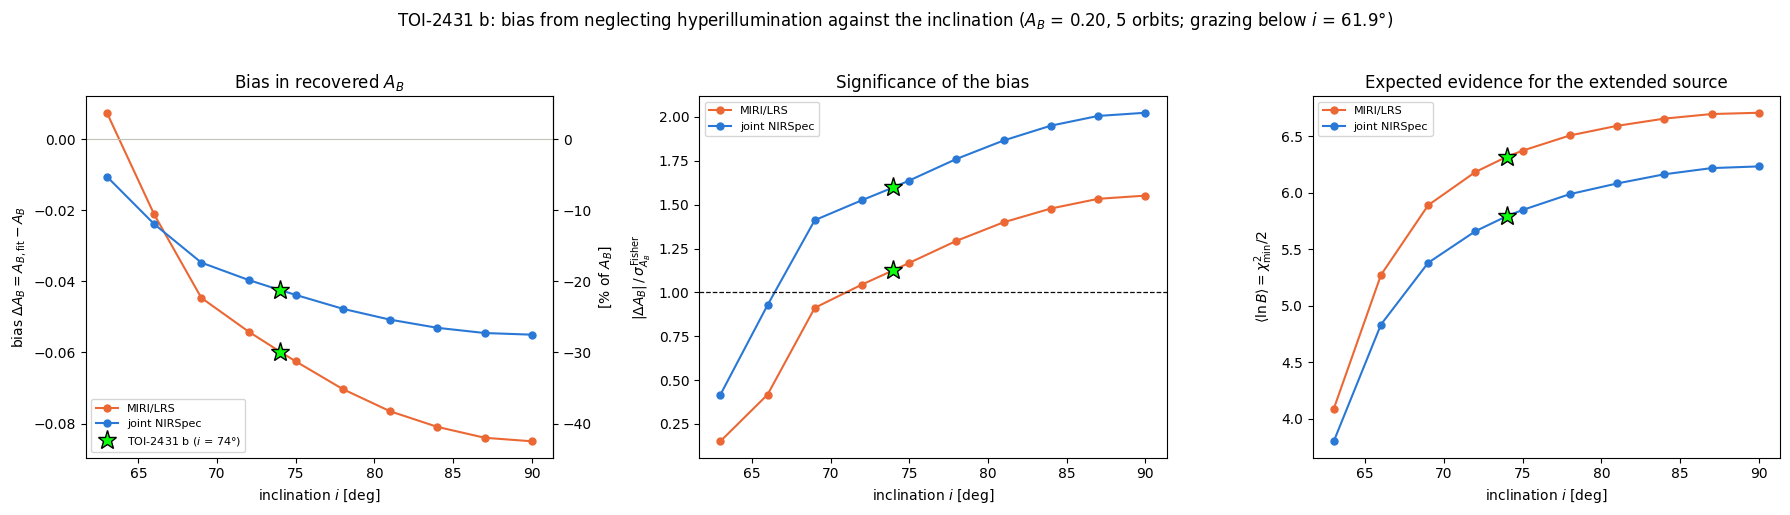

TOI-2431 b, MIRI/LRS  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
    90    0.115   -0.085 0.05478       1.552 13.41     6.707
    87    0.116   -0.084 0.05479       1.533 13.39     6.695
    84   0.1191 -0.08095 0.05477       1.478 13.31     6.655
    81   0.1234 -0.07656  0.0547         1.4 13.18     6.591
    78   0.1297 -0.07034 0.05438       1.294 13.01     6.506
    75   0.1375 -0.06252 0.05353       1.168 12.74     6.371
    74   0.1402 -0.05978 0.05308       1.126 12.64     6.318
    72   0.1459 -0.05413 0.05182       1.045 12.37     6.183
    69   0.1554 -0.04464 0.04897      0.9116 11.78     5.889
    66   0.1789 -0.02114 0.05073      0.4167 10.54     5.271
    63   0.2074 0.007436 0.04931      0.1508 8.173     4.087 

TOI-2431 b, joint NIRSpec  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
    90    0.145   -0.055 0.02717       2.024 12.46     6.232
    87   0.1455 -0.05453 0.02719       

In [6]:
PAPER_MODE = False
# Modes of the sweeps (sections 4 and 5): MIRI/LRS and the joint NIRSpec fit, each at the planet's own noise; independent of `instrument` above
SWEEP_MODES = {"MIRI/LRS": "MIRI/LRS", "joint NIRSpec": tuple(JWST_BANDS[:2])}
kw_sweep = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)
sweep_cfgs = {label: retrieval_cfg(cfg, planet, ins) for label, ins in SWEEP_MODES.items()}

i_graze = np.degrees(np.arccos((1. - planet.r1 / planet.r2) / (planet.R / planet.r2)))   # b = 1 - Rp/R*: below it the occultation is grazing
incl_grid = np.unique(np.concatenate([np.linspace(np.ceil(i_graze + 1.), 90., 10), [planet.incl]]))[::-1]
sweeps_i = {label: bias_sweep(c, A_B_true, incl_grid, cfg_with_incl, models=("naive",), **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_i, A_B_true, r"inclination $i$ [deg]", joint=False, mark=planet.incl, mark_label=f"{planet.name} ($i$ = {planet.incl:g}°)",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the inclination ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits; grazing below $i$ = {i_graze:.1f}°)")
paper_figure(f"abbias_vs_incl_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
for label, t in sweeps_i.items():
    print(f"{planet.name}, {label}  (value = inclination [deg])")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "chi2", "lnB_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")

**A planet read off the map against its own inclination.** The same two-point comparison for other planets (`check_planets`), in the first mode of `SWEEP_MODES`: the $A_B$-only fit at $i = 90°$, where the map places the planet, and at its own inclination. The printed relative biases show how much of the difference between a map value and the per-planet fit is the inclination alone.

In [7]:
check_planets = ("TOI-2260 b",)   # planets with a large impact parameter, whose map value overstates their own-geometry bias
mode0 = next(iter(SWEEP_MODES))
for nm in check_planets:
    pl_ = hi_planets_by_name(nm)
    t = bias_sweep(retrieval_cfg(cfg, pl_, SWEEP_MODES[mode0]), A_B_true, (90., pl_.incl), cfg_with_incl, models=("naive",), **kw_sweep)
    b = pl_.R / pl_.r2 * np.cos(np.radians(pl_.incl))
    print(f"{nm} ({mode0}, a/R* = {pl_.R / pl_.r2:.2f}, b = {b:.2f}): bias {t['bias'][0]:+.4f} ({100 * t['bias'][0] / A_B_true:+.0f} %) at i = 90 deg,  {t['bias'][1]:+.4f} ({100 * t['bias'][1] / A_B_true:+.0f} %) at its own i = {pl_.incl:g} deg;  "
          f"|bias|/sigma {t['bias_sigma'][0]:.2f} -> {t['bias_sigma'][1]:.2f}")

TOI-2260 b (MIRI/LRS, a/R* = 2.22, b = 0.77): bias -0.0770 (-39 %) at i = 90 deg,  -0.0282 (-14 %) at its own i = 69.7 deg;  |bias|/sigma 0.53 -> 0.21


### 5. Bias vs. the limb darkening $u_B$ of the irradiance

The bolometric linear limb darkening $u_B$ of the stellar disc enters only the extended-source truth: the point-source models have no $u_B$. The sweep (`bias_sweep` with `cfg_with_u_B`) therefore changes the truth alone and refits it, for the $A_B$-only fit in the two modes of section 4; the baseline value is the green star.

What to look for: how little the bias moves across the range of plausible bolometric limb-darkening coefficients, and the somewhat stronger dependence of the expected evidence (a more limb-darkened star puts less light into the penumbra).

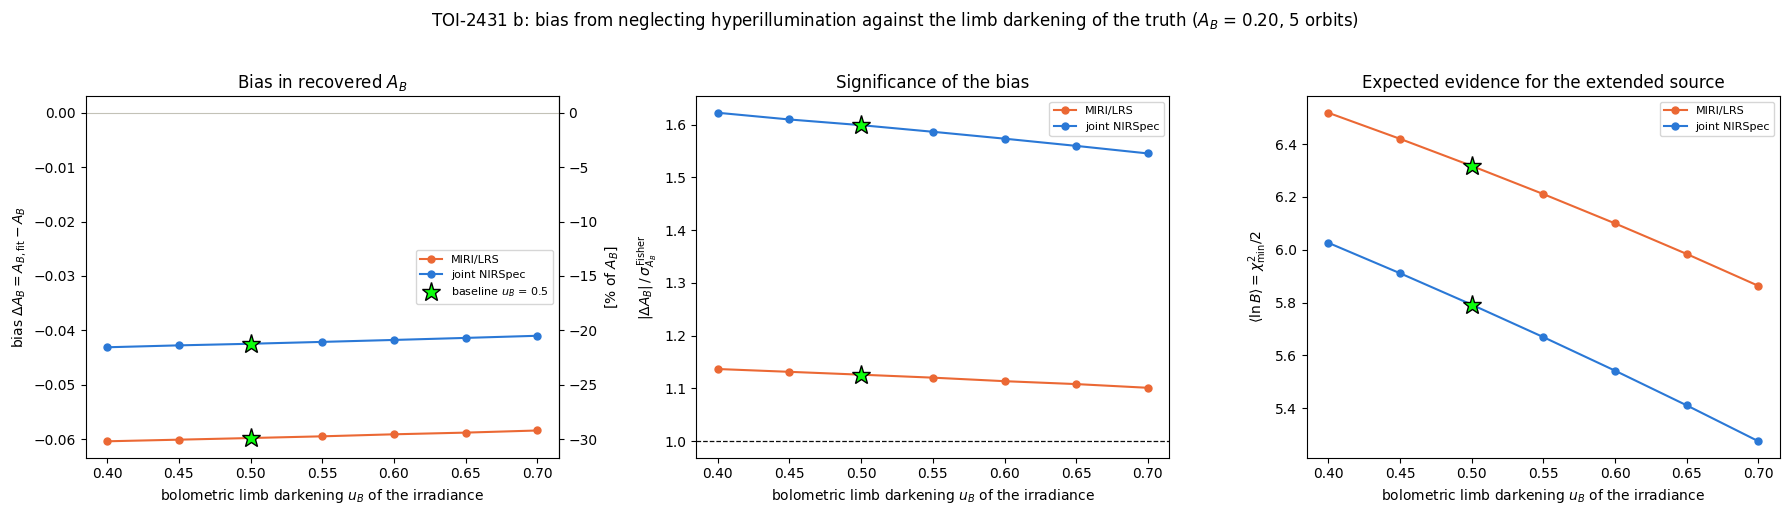

TOI-2431 b, MIRI/LRS  (value = u_B)
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
   0.4   0.1396 -0.06038 0.05311       1.137 13.04     6.519
  0.45   0.1399 -0.06008  0.0531       1.132 12.84      6.42
   0.5   0.1402 -0.05978 0.05308       1.126 12.64     6.318
  0.55   0.1405 -0.05946 0.05307       1.121 12.42     6.211
   0.6   0.1409 -0.05909 0.05305       1.114  12.2       6.1
  0.65   0.1412 -0.05878 0.05304       1.108 11.97     5.984
   0.7   0.1416 -0.05839 0.05302       1.101 11.73     5.863 

TOI-2431 b, joint NIRSpec  (value = u_B)
 value  A_B_fit     bias   sigma  bias_sigma  chi2  lnB_mean
   0.4   0.1569  -0.0431 0.02657       1.622 12.05     6.026
  0.45   0.1573 -0.04275 0.02656        1.61 11.82     5.911
   0.5   0.1575 -0.04245 0.02655       1.599 11.58     5.792
  0.55   0.1579 -0.04211 0.02655       1.586 11.34     5.669
   0.6   0.1582 -0.04175 0.02654       1.573 11.08     5.542
  0.65   0.1586 -0.04138 0.02653       1.559 10.82      5.41
   0.7

In [8]:
PAPER_MODE = False
u_B_grid = np.unique(np.round(np.concatenate([np.arange(0.40, 0.701, 0.05), [u_B]]), 6))
sweeps_u = {label: bias_sweep(c, A_B_true, u_B_grid, cfg_with_u_B, models=("naive",), **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_u, A_B_true, r"bolometric limb darkening $u_B$ of the irradiance", joint=False, mark=u_B, mark_label=f"baseline $u_B$ = {u_B:g}",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the limb darkening of the truth ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits)")
paper_figure(f"abbias_vs_uB_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
for label, t in sweeps_u.items():
    print(f"{planet.name}, {label}  (value = u_B)")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "chi2", "lnB_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")